In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# SSTO Earth Launch

This example is based on the _Time-Optimal Launch of a Titan II_
example given in Appendix B of Longuski {cite}`longuski2014optimal`.
It finds the pitch profile for a single-stage-to-orbit launch vehicle that minimizes the time
required to reach orbit insertion under constant thrust.

![The free-body-diagram of the single-stage-to-orbit problem.](ssto_fbd.png)

The vehicle dynamics are given by

\begin{align}
  \frac{dx}{dt} &= v_x \\
  \frac{dy}{dt} &= v_y \\
  \frac{dv_x}{dt} &= \frac{1}{m} (T \cos \theta - D \cos \gamma) \\
  \frac{dv_y}{dt} &= \frac{1}{m} (T \sin \theta - D \sin \gamma) - g \\
  \frac{dm}{dt} &= \frac{T}{g I_{sp}}
\end{align}

The initial conditions are

\begin{align}
  x_0 &= 0 \\
  y_0 &= 0 \\
  v_{x0} &= 0 \\
  v_{y0} &= 0 \\
  m_0 &= 117000 \rm{\,kg}
\end{align}

and the final conditions are

\begin{align}
  x_f &= \rm{free} \\
  y_f &= 185 \rm{\,km} \\
  v_{xf} &= V_{circ} \\
  v_{yf} &= 0 \\
  m_f &= \rm{free}
\end{align}

## Defining the ODE

Generally, one could define the ODE system as a composite group of multile components.
The atmosphere component computes density ($\rho$).
The eom component computes the state rates.
Decomposing the ODE into smaller calculations makes it easier to derive the analytic derivatives.

![The notional XDSM diagram for the ODE system in the SSTO problem.](ssto_xdsm.png)

However, for this example we will demonstrate the use of complex-step differentiation and define the ODE as a single component.
This saves time up front in the deevlopment of the ODE at a minor cost in execution time.

The unconnected inputs to the EOM at the top of the diagram are provided by the Dymos phase as states, controls, or time values.
The outputs, including the state rates, are shown on the right side of the diagram.
The Dymos phases use state rate values to ensure that the integration technique satisfies the dynamics of the system.

In [2]:
import openmdao.api as om
import numpy as np


class LaunchVehicleODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int,
                             desc='Number of nodes to be evaluated in the RHS')

        self.options.declare('g', types=float, default=9.80665,
                             desc='Gravitational acceleration, m/s**2')

        self.options.declare('rho_ref', types=float, default=1.225,
                             desc='Reference atmospheric density, kg/m**3')

        self.options.declare('h_scale', types=float, default=8.44E3,
                             desc='Reference altitude, m')

        self.options.declare('CD', types=float, default=0.5,
                             desc='coefficient of drag')

        self.options.declare('S', types=float, default=7.069,
                             desc='aerodynamic reference area (m**2)')

    def setup(self):
        nn = self.options['num_nodes']

        self.add_input('y',
                       val=np.zeros(nn),
                       desc='altitude',
                       units='m')

        self.add_input('vx',
                       val=np.zeros(nn),
                       desc='x velocity',
                       units='m/s')

        self.add_input('vy',
                       val=np.zeros(nn),
                       desc='y velocity',
                       units='m/s')

        self.add_input('m',
                       val=np.zeros(nn),
                       desc='mass',
                       units='kg')

        self.add_input('theta',
                       val=np.zeros(nn),
                       desc='pitch angle',
                       units='rad')

        self.add_input('thrust',
                       val=2100000 * np.ones(nn),
                       desc='thrust',
                       units='N')

        self.add_input('Isp',
                       val=265.2 * np.ones(nn),
                       desc='specific impulse',
                       units='s')
        # Outputs
        self.add_output('xdot',
                        val=np.zeros(nn),
                        desc='velocity component in x',
                        units='m/s')

        self.add_output('ydot',
                        val=np.zeros(nn),
                        desc='velocity component in y',
                        units='m/s')

        self.add_output('vxdot',
                        val=np.zeros(nn),
                        desc='x acceleration magnitude',
                        units='m/s**2')

        self.add_output('vydot',
                        val=np.zeros(nn),
                        desc='y acceleration magnitude',
                        units='m/s**2')

        self.add_output('mdot',
                        val=np.zeros(nn),
                        desc='mass rate of change',
                        units='kg/s')

        self.add_output('rho',
                        val=np.zeros(nn),
                        desc='density',
                        units='kg/m**3')

        # Setup partials
        # Complex-step derivatives
        self.declare_coloring(wrt='*', method='cs')

    def compute(self, inputs, outputs):

        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        vx = inputs['vx']
        vy = inputs['vy']
        m = inputs['m']
        F_T = inputs['thrust']
        Isp = inputs['Isp']
        y = inputs['y']

        g = self.options['g']
        rho_ref = self.options['rho_ref']
        h_scale = self.options['h_scale']

        CDA = self.options['CD'] * self.options['S']

        outputs['rho'] = rho_ref * np.exp(-y / h_scale)
        outputs['xdot'] = vx
        outputs['ydot'] = vy
        outputs['vxdot'] = (F_T * cos_theta - 0.5 * CDA * outputs['rho'] * vx**2) / m
        outputs['vydot'] = (F_T * sin_theta - 0.5 * CDA * outputs['rho'] * vy**2) / m - g
        outputs['mdot'] = -F_T / (g * Isp)


## Solving the problem

In [3]:
%matplotlib inline

In [4]:
import matplotlib.pyplot as plt
import openmdao.api as om
import dymos as dm

#
# Setup and solve the optimal control problem
#
p = om.Problem(model=om.Group())
p.driver = om.pyOptSparseDriver()
p.driver.declare_coloring(tol=1.0E-12)

#
# Initialize our Trajectory and Phase
#
traj = dm.Trajectory()

phase = dm.Phase(ode_class=LaunchVehicleODE,
                 transcription=dm.GaussLobatto(num_segments=12, order=3, compressed=False))

traj.add_phase('phase0', phase)
p.model.add_subsystem('traj', traj)

#
# Set the options for the variables
#
phase.set_time_options(fix_initial=True, duration_bounds=(10, 500))

phase.add_state('x', fix_initial=True, ref=1.0E5, defect_ref=10000.0,
                rate_source='xdot')
phase.add_state('y', fix_initial=True, ref=1.0E5, defect_ref=10000.0,
                rate_source='ydot')
phase.add_state('vx', fix_initial=True, ref=1.0E3, defect_ref=1000.0,
                rate_source='vxdot')
phase.add_state('vy', fix_initial=True, ref=1.0E3, defect_ref=1000.0,
                rate_source='vydot')
phase.add_state('m', fix_initial=True, ref=1.0E3, defect_ref=100.0,
                rate_source='mdot')

phase.add_control('theta', units='rad', lower=-1.57, upper=1.57, targets=['theta'])
phase.add_parameter('thrust', units='N', opt=False, val=2100000.0, targets=['thrust'])

#
# Set the options for our constraints and objective
#
phase.add_boundary_constraint('y', loc='final', equals=1.85E5, linear=True)
phase.add_boundary_constraint('vx', loc='final', equals=7796.6961)
phase.add_boundary_constraint('vy', loc='final', equals=0)

phase.add_objective('time', loc='final', scaler=0.01)

p.model.linear_solver = om.DirectSolver()

#
# Setup and set initial values
#
p.setup(check=True)

phase.set_time_val(initial=0.0, duration=150.0)
phase.set_state_val('x', [0, 1.15E5])
phase.set_state_val('y', [0, 1.85E5])
phase.set_state_val('vy', [1.0E-6, 0])
phase.set_state_val('m', [117000, 1163])
phase.set_control_val('theta', [1.5, -0.76])
phase.set_parameter_val('thrust', 2.1, units='MN')

#
# Solve the Problem
#
dm.run_problem(p, simulate=True)

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.000662 sec).


INFO: checking system...


INFO:     system check complete (0.000024 sec).


INFO: checking solvers...


...


Jacobian shape: (74, 152)  (4.63% nonzero)
FWD solves: 12   REV solves: 0
Total colors vs. total size: 12 vs 152  (92.11% improvement)

Sparsity computed using tolerance: 1e-12.
Dense total jacobian for Problem 'ssto_earth' was computed 3 times.
Time to compute sparsity:   0.3025 sec
Time to compute coloring:   0.1783 sec
Memory to compute coloring:   0.2227 MB
Coloring created on: 2026-10-30 15:46:14




Optimization Problem -- Optimization using pyOpt_sparse
    Objective Function: _objfunc

    Solution: 
--------------------------------------------------------------------------------
    Total Time:                   29.1698
       User Objective Time :       9.1959
       User Sensitivity Time :    10.7142
       Interface Time :            3.4543
       Opt Solver Time:            5.8053
    Calls to Objective Function :    4907
    Calls to Sens Function :          501


   Objectives
      Index  Name                     Value
          0  traj.phase0.t     1.431610E+00

   Variables (c - continuous, i - integer, d - discrete)
      Index  Name                            Type      Lower Bound            Value      Upper Bound     Status
          0  traj.phase0.t_duration_0           c     1.000000E+01     1.431610E+02     5.000000E+02           
          1  traj.phase0.states:x_0             c    -1.000000E+20     1.487979E-03     1.000000E+20           
          2  traj.ph


Simulating trajectory traj


Done simulating trajectory traj


Problem: ssto_earth
Driver:  pyOptSparseDriver
  success     : False
  iterations  : 4909
  runtime     : 2.9760E+01 s
  model_evals : 4909
  model_time  : 5.9525E+00 s
  deriv_evals : 502
  deriv_time  : 1.0629E+01 s
  exit_status : FAIL

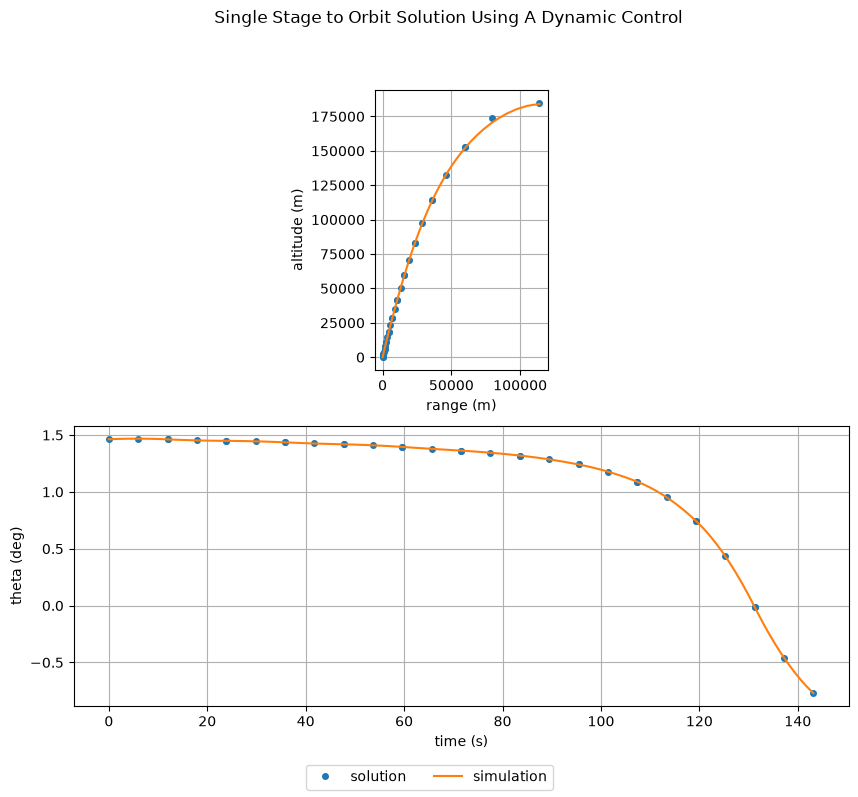

In [5]:
sol = om.CaseReader(p.get_outputs_dir() / 'dymos_solution.db').get_case('final')
sim = om.CaseReader(traj.sim_prob.get_outputs_dir() / 'dymos_simulation.db').get_case('final')

fig, [traj_ax, control_ax] = plt.subplots(nrows=2, ncols=1, figsize=(10, 8))

traj_ax.plot(sol.get_val('traj.phase0.timeseries.x'),
             sol.get_val('traj.phase0.timeseries.y'),
             marker='o',
             ms=4,
             linestyle='None',
             label='solution')

traj_ax.plot(sim.get_val('traj.phase0.timeseries.x'),
             sim.get_val('traj.phase0.timeseries.y'),
             marker=None,
             linestyle='-',
             label='simulation')

traj_ax.set_xlabel('range (m)')
traj_ax.set_ylabel('altitude (m)')
traj_ax.set_aspect('equal')
traj_ax.grid(True)

control_ax.plot(sol.get_val('traj.phase0.timeseries.time'),
             sol.get_val('traj.phase0.timeseries.theta'),
             marker='o',
             ms=4,
             linestyle='None')

control_ax.plot(sim.get_val('traj.phase0.timeseries.time'),
             sim.get_val('traj.phase0.timeseries.theta'),
             linestyle='-',
             marker=None)

control_ax.set_xlabel('time (s)')
control_ax.set_ylabel('theta (deg)')
control_ax.grid(True)

plt.suptitle('Single Stage to Orbit Solution Using A Dynamic Control')
fig.legend(loc='lower center', ncol=2)

plt.show()

In [6]:
from openmdao.utils.assert_utils import assert_near_equal

assert_near_equal(p.get_val('traj.phase0.timeseries.time')[-1], 143, tolerance=0.05)
assert_near_equal(p.get_val('traj.phase0.timeseries.y')[-1], 1.85E5, 1e-4)
assert_near_equal(p.get_val('traj.phase0.timeseries.vx')[-1], 7796.6961, 1e-4)
assert_near_equal(p.get_val('traj.phase0.timeseries.vy')[-1], 0, 1e-4)

np.float64(1.4983829342939135e-18)

## References

```{bibliography}
:filter: docname in docnames
```